# Narrative perspective in English and German creative-writing manuals

## Full analysis (v2)

**Audience:** colleagues in literary studies, narratology and creative writing.

**Important:** figures below are **observed retrieval patterns** from a bilingual dictionary, not validated linguistic annotations. Precision, recall and F1 remain pending until the evaluation sample is labelled.

This notebook reads precomputed `reports/tables/02_*.csv` artifacts. It does not rescan full texts and does not print passage text.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'reports' / 'tables').exists() and (ROOT / '..' / 'reports' / 'tables').exists():
    ROOT = (ROOT / '..').resolve()
TABLES = ROOT / 'reports' / 'tables'
FIGURES = ROOT / 'reports' / 'figures' / '02_narrative_perspective'
META = json.loads((ROOT / 'reports' / '02_narrative_perspective_run_meta.json').read_text())

def load_t(name):
    return pd.read_csv(TABLES / f'02_{name}.csv')

def show_fig(name, caption):
    png = FIGURES / f'{name}.png'
    display(Markdown(f'**Figure.** {caption}'))
    if png.is_file():
        display(Image(filename=str(png)))
    else:
        display(Markdown(f'*Missing figure:* `{png}`'))

print('Snapshot:', META.get('corpus_snapshot_id'))
print('Lexicon:', META.get('lexicon_version'))
print('Retrieval execution:', META.get('retrieval_execution_id'))
print('Analysis:', META.get('analysis_version'))
print('Commit:', META.get('source_commit'))
print('Bootstrap iters:', META.get('bootstrap_iterations'))


Snapshot: corpus_snapshot_analysis_v1_candidate_20261122
Lexicon: 0.3-draft
Retrieval execution: v03_lexical_bm25_20261122
Analysis: v2
Commit: 124f0683c6ad7b26a81cd20ca24ccf2c5be9cdbd
Bootstrap iters: 1000


## 1. Corpus overview

1. **Research question.** How large are the English and German analysis corpora, and how are they composed?
2. **Method.** Counts from the v1 candidate book and passage manifests. Eligible words = sum of passage `word_count` (≥40 characters). Body words are supplementary.
3. **Results.** See the overview table and funnel figure.
4. **Interpretation.** The English analysis set is much larger than the German set. Category mix also differs (German contrast materials take a larger word share).
5. **Limitation.** Exclusions follow documented rules (`needs_ocr`, `short_text`, `surplus_duplicate`, `role_conflict`); they are not silent drops.
6. **Further work.** Improve `work_id` coverage before claiming edition-independent deduplication.


,language,language_label,listed_books,analysis_set_books,excluded_books,n_authors,eligible_words,body_words,eligible_paragraphs
0,en,English,503,442,61,408,34218544.0,34581264.0,315302
1,de,German,78,67,11,56,4619105.0,4665385.0,42623


,language,language_label,listed_books,books_with_available_text,successfully_preprocessed_or_ruled,books_included_in_retrieval,books_with_at_least_one_match,books_without_matches,books_excluded,analysis_books_flagged_potential_duplicate,excluded_needs_ocr,excluded_short_text,excluded_surplus_duplicate,excluded_role_conflict,total_eligible_passage_words,total_cleaned_body_words
0,en,English,503,486,486,442,407,35,61,27,17,17,23,4,34218544.0,34581264.0
1,de,German,78,77,77,67,67,0,11,4,1,5,5,0,4619105.0,4665385.0


**Figure.** Pipeline coverage by language (listed → available text → retrieval → matches / exclusions).

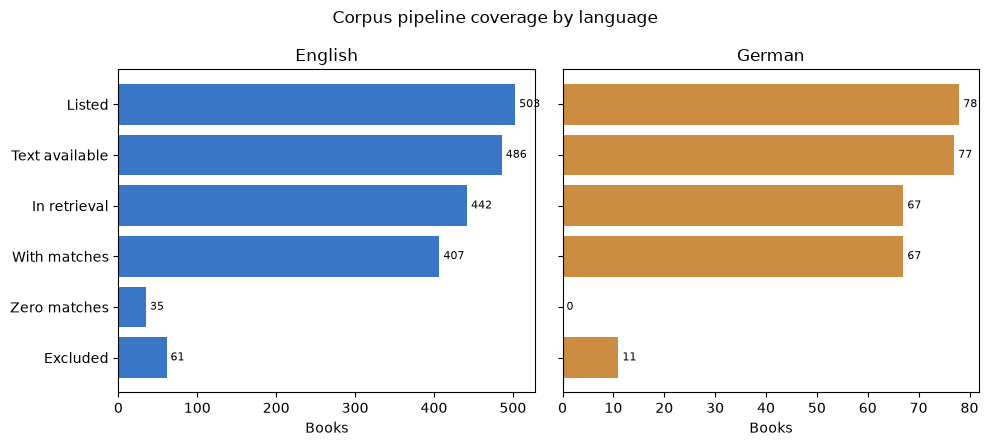

**Figure.** Distribution of book eligible-word counts (log10). Medians describe a typical book; long right tails are large manuals.

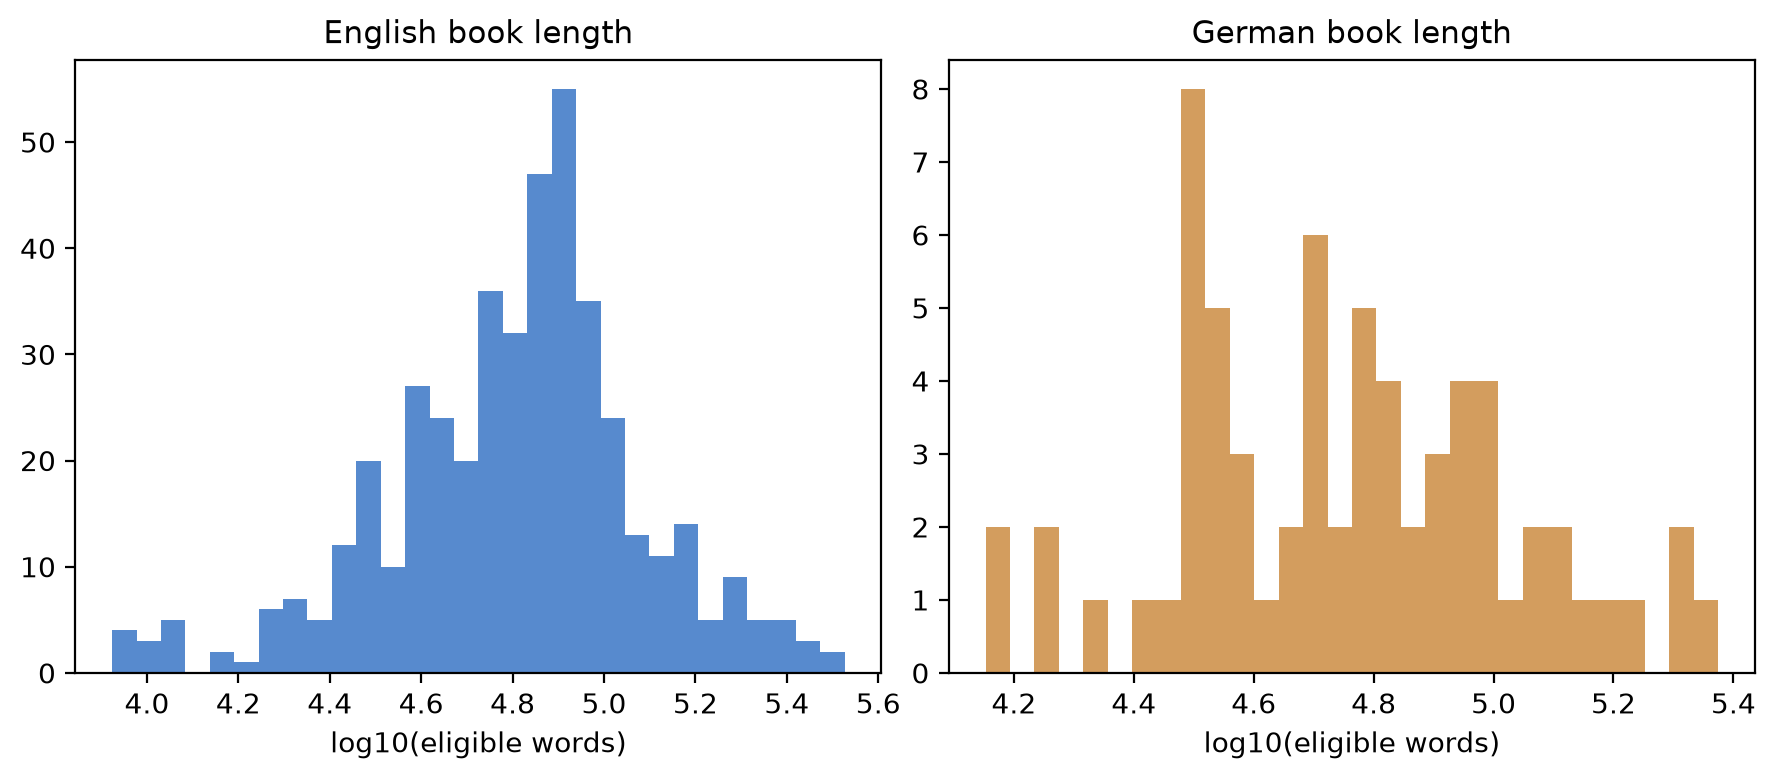

**Figure.** Distribution of eligible paragraph lengths (log10 words).

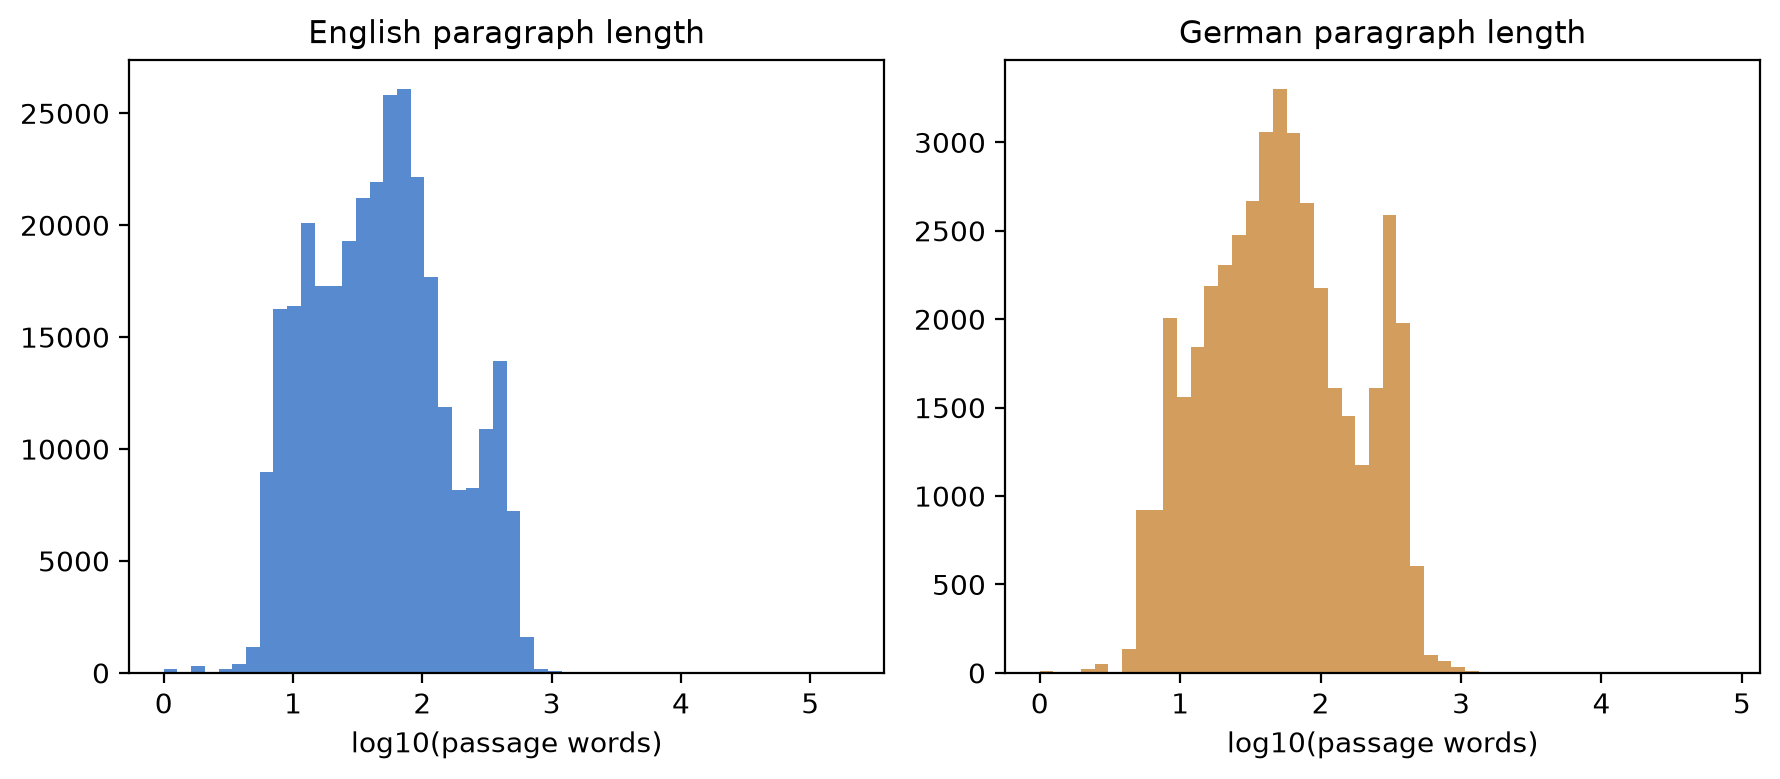

In [2]:
overview = load_t('corpus_overview')
funnel = load_t('pipeline_funnel')
display(overview)
display(funnel)
show_fig('01_pipeline_funnel', 'Pipeline coverage by language (listed → available text → retrieval → matches / exclusions).')
show_fig('03_book_length', 'Distribution of book eligible-word counts (log10). Medians describe a typical book; long right tails are large manuals.')
show_fig('04_paragraph_length', 'Distribution of eligible paragraph lengths (log10 words).')


## 2. Data quality: word counts and extreme passages

1. **Question.** Why do body-word totals disagree with eligible-passage sums for many books?
2. **Method.** Compare `cleaned_body_word_count` with `eligible_passage_word_count` per book; diagnose passages ≥100k characters using JSON structure (newlines / blank breaks).
3. **Results.** Discrepancies are expected: short paragraphs count toward body words but not eligible passages. Extreme passages (56) lack recoverable blank-line structure; the resegment gate did **not** fire.
4. **Interpretation.** Primary rates should use eligible searchable text. Treat body-word rates as supplementary.
5. **Limitation.** Collapsed chapters without internal breaks cannot be safely resegmented automatically.
6. **Further work.** Improve extraction/segmentation upstream for future embedding pipelines.


Books with |body-eligible|>1: 428 / 509


classification
ocr_artifact_collapsed                       27
concatenated_or_unsegmented_chapter          19
oversized_paragraph_in_multi_para_chapter    10
Name: count, dtype: int64

,passage_id,book_id,language,primary_group,character_count,word_count,qc_flags,n_paragraphs_in_chapter,n_newlines,n_blank_breaks,classification,recoverable_for_resegment,gate_action
0,en_095dc8c98f5b:c5:p0,en_095dc8c98f5b,en,fiction_manual,231828,42146,extreme_length;possible_ocr_spacing,6,0,0,ocr_artifact_collapsed,False,retain_original
1,en_095dc8c98f5b:c7:p0,en_095dc8c98f5b,en,fiction_manual,301906,53957,extreme_length;possible_ocr_spacing,1,0,0,ocr_artifact_collapsed,False,retain_original
2,en_1b0f06390fb7:c3:p0,en_1b0f06390fb7,en,pedagogy_genre_craft,733877,126116,extreme_length;possible_ocr_spacing,1,0,0,ocr_artifact_collapsed,False,retain_original
3,en_214c71ed2710:c4:p0,en_214c71ed2710,en,fiction_manual,452426,78393,extreme_length,1,0,0,concatenated_or_unsegmented_chapter,False,retain_original
4,en_28deda9732cd:c35:p0,en_28deda9732cd,en,fiction_manual,131199,21331,extreme_length,1,0,0,concatenated_or_unsegmented_chapter,False,retain_original


**Figure.** Eligible passage character-length distributions with 100k threshold.

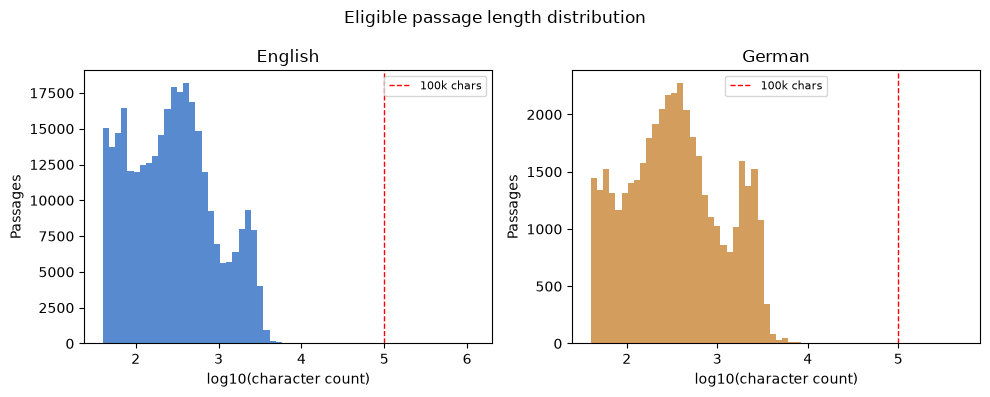

In [3]:
disc = load_t('wordcount_discrepancy')
ext = load_t('extreme_passages')
print('Books with |body-eligible|>1:', int((disc.absolute_discrepancy_body_minus_eligible.abs()>1).sum()), '/', len(disc))
display(ext['classification'].value_counts())
display(ext.head())
show_fig('02_passage_length_distribution', 'Eligible passage character-length distributions with 100k threshold.')


## 3. Overall retrieval coverage

1. **Question.** How much of each language corpus is retrieved by lexical matching?
2. **Method.** Unique passages and passage–concept assignments from lexical v0.3, normalized by eligible words.
3. **Results.** Coverage table below.
4. **Interpretation.** Assignments ≥ passages because one paragraph can match several concepts.
5. **Limitation.** Coverage is dictionary reach, not prevalence of the theoretical phenomenon.
6. **Further work.** Annotated evaluation for precision/recall.


In [4]:
cov = load_t('retrieval_coverage')
display(cov)


,language,language_label,retrieved_passages,assignments,books_with_matches,pct_books_with_matches,pct_eligible_paragraphs,passages_per_10k_eligible_words,assignments_per_10k_eligible_words,avg_concepts_per_retrieved_passage,concepts_nonzero,n_concepts_configured,eligible_words,eligible_paragraphs,n_analysis_books
0,en,English,7380,10643,407,92.081448,2.340613,2.156725,3.110302,1.442141,36,36,34218544.0,315302.0,442
1,de,German,941,1380,67,100.000000,2.207728,2.037191,2.987592,1.466525,32,36,4619105.0,42623.0,67


## 4. All retrieval concepts

1. **Question.** Which concepts are frequent in each language?
2. **Method.** Absolute counts, eligible-word rates, body-word rates, book prevalence. Zero-frequency concepts retained. Ratios use undefined/infinite when German is zero.
3. **Results.** Full frequency table and top-15 figure.
4. **Interpretation.** Compare rates, not only raw counts, because corpus sizes differ.
5. **Limitation.** Asymmetric dictionaries can create asymmetric rates.
6. **Further work.** Colleague terminology review via the interactive HTML report.


,concept_id,concept_label,language,language_label,n_assignments,n_unique_passages,n_books,eligible_words,body_words,eligible_paragraphs,...,percentage_of_books,median_book_frequency,method,version,denominator_note,concept_family,concept_family_label,frequency_ratio_en_over_de,abs_diff_en_minus_de_per_10k,ratio_note
38,grammatical_first_person,grammatical first person,de,German,247,247,47,4619105.0,4665385.0,42623.0,...,70.149254,0.321007,lexical,v03,primary=eligible_passage_words; supplementary=...,perspective_and_person,Narrative perspective and grammatical person,1.371744,0.198785,NaN
36,perspective_general,perspective general,de,German,218,218,38,4619105.0,4665385.0,42623.0,...,56.716418,0.193255,lexical,v03,primary=eligible_passage_words; supplementary=...,perspective_and_person,Narrative perspective and grammatical person,0.784542,-0.101686,NaN
49,focalization_zero,focalization zero,de,German,133,133,34,4619105.0,4665385.0,42623.0,...,50.746269,0.065838,lexical,v03,primary=eligible_passage_words; supplementary=...,focalization,Focalization,1.031189,0.008980,NaN
46,stance_narratorial,stance narratorial,de,German,103,103,25,4619105.0,4665385.0,42623.0,...,37.313433,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,narratorial_figural_stance,Narratorial and figural stance,0.020969,-0.218311,NaN
62,switching_consistency,switching consistency,de,German,94,94,29,4619105.0,4665385.0,42623.0,...,43.283582,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,consciousness_and_techniques,Consciousness and writing techniques,0.086163,-0.185968,NaN
40,grammatical_third_person,grammatical third person,de,German,89,89,34,4619105.0,4665385.0,42623.0,...,50.746269,0.047393,lexical,v03,primary=eligible_passage_words; supplementary=...,perspective_and_person,Narrative perspective and grammatical person,3.080465,0.400860,NaN
47,stance_figural,stance figural,de,German,75,75,17,4619105.0,4665385.0,42623.0,...,25.373134,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,narratorial_figural_stance,Narratorial and figural stance,0.032397,-0.157109,NaN
60,thought_representation,thought representation,de,German,63,63,24,4619105.0,4665385.0,42623.0,...,35.820896,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,consciousness_and_techniques,Consciousness and writing techniques,0.807787,-0.026216,NaN
37,voice_general,voice general,de,German,53,53,15,4619105.0,4665385.0,42623.0,...,22.388060,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,perspective_and_person,Narrative perspective and grammatical person,1.115564,0.013260,NaN
66,narrator_level_time,narrator level time,de,German,45,45,12,4619105.0,4665385.0,42623.0,...,17.910448,0.000000,lexical,v03,primary=eligible_passage_words; supplementary=...,functions_and_reader_effects,Narrative functions and reader effects,0.086992,-0.088947,NaN


**Figure.** Top 15 concepts by assignments per 10k eligible words.

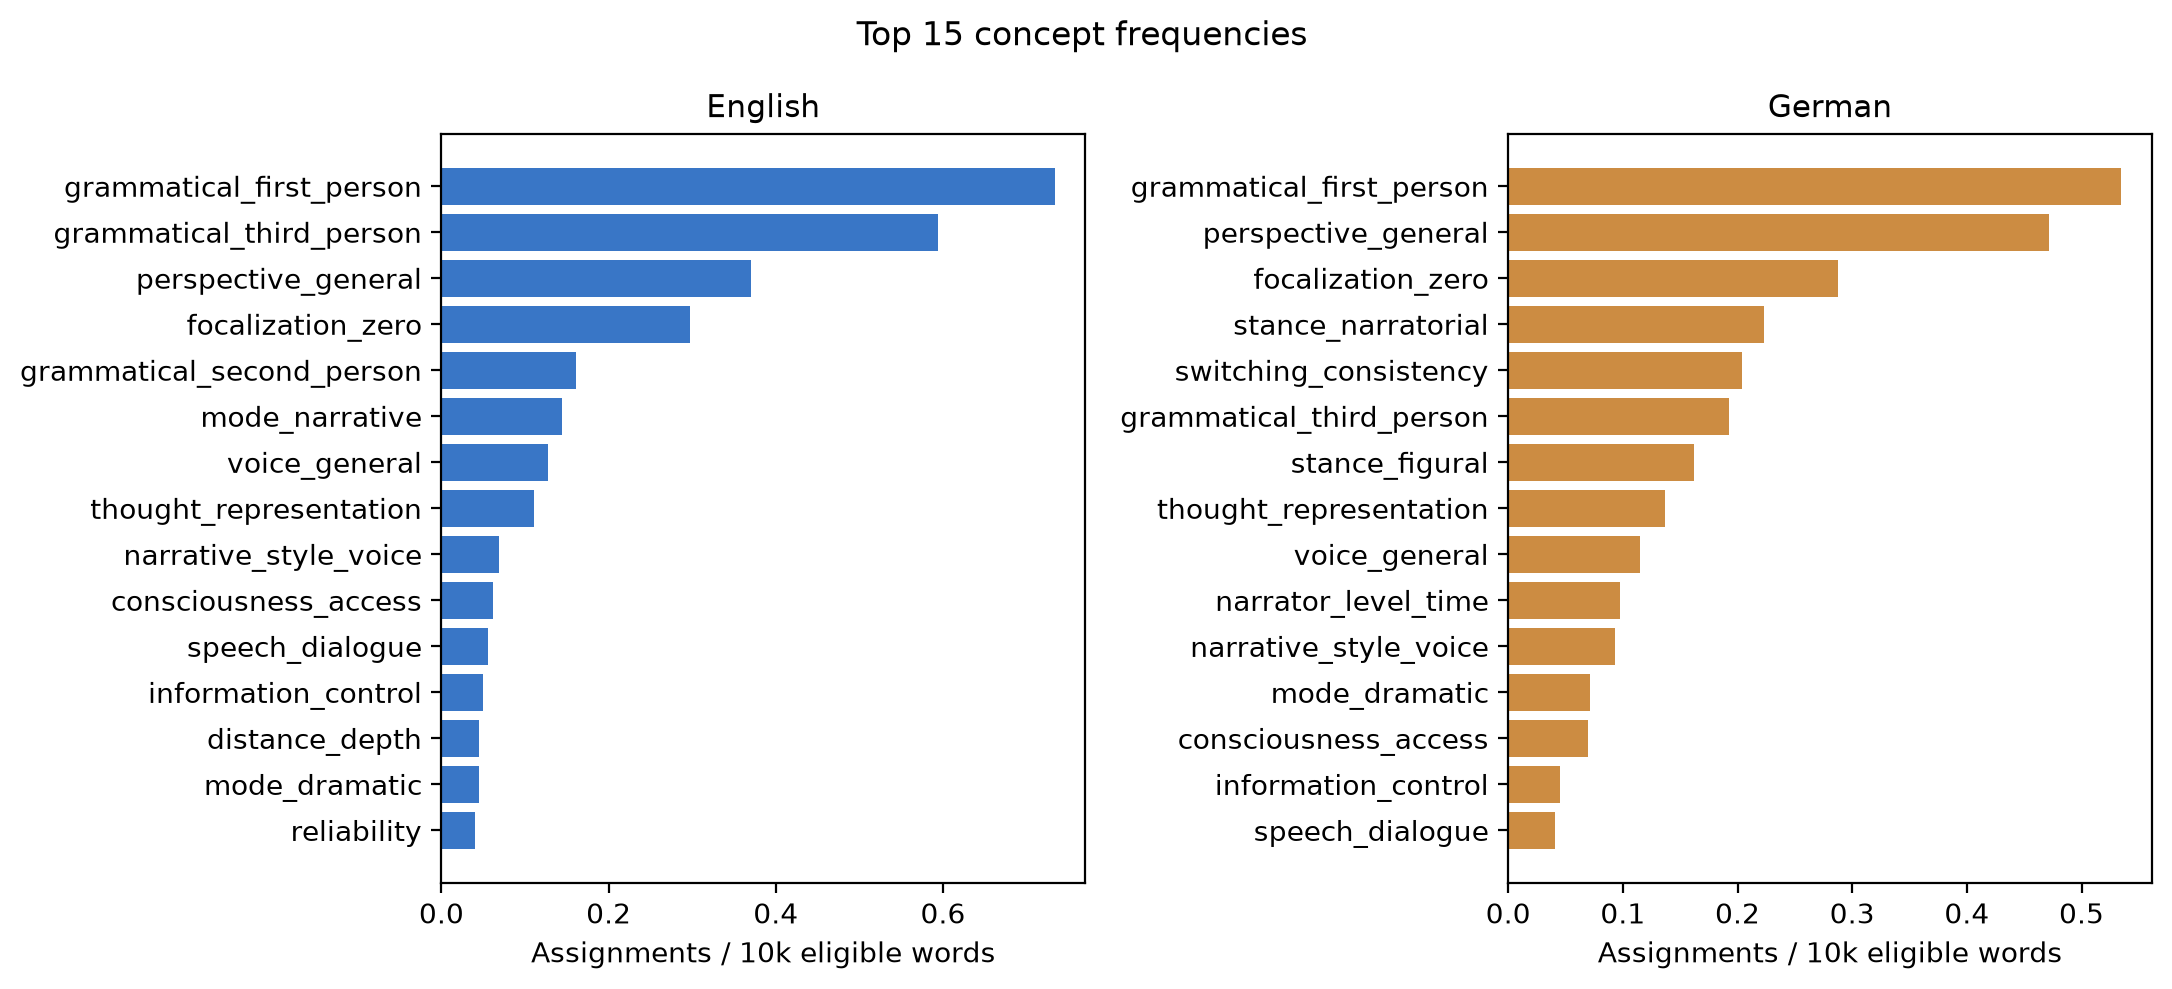

In [5]:
freq = load_t('concept_frequencies')
assert freq.concept_id.nunique() == META['n_concepts']
assert set(freq.language) == {'en','de'}
assert len(freq) == META['n_concepts'] * 2
display(freq.sort_values(['language','frequency_per_10000_eligible_words'], ascending=[True, False]).head(20))
show_fig('05_concept_frequencies_top15', 'Top 15 concepts by assignments per 10k eligible words.')


## 5. Concept families

Family rates deduplicate passages within each family. Passages may belong to several families — do not sum family frequencies into a grand total.


,concept_family,concept_family_label,language,language_label,n_assignments,n_unique_passages,eligible_words,frequency_per_10000_eligible_words,note,method,version
0,perspective_and_person,Narrative perspective and grammatical person,en,English,6798,5178,34218544.0,1.513215,numerator = unique passages in family (dedupli...,lexical,v03
1,perspective_and_person,Narrative perspective and grammatical person,de,German,619,494,4619105.0,1.069471,numerator = unique passages in family (dedupli...,lexical,v03
2,narrator_participation,Narrator participation,en,English,92,89,34218544.0,0.026009,numerator = unique passages in family (dedupli...,lexical,v03
3,narrator_participation,Narrator participation,de,German,7,7,4619105.0,0.015154,numerator = unique passages in family (dedupli...,lexical,v03
4,narratorial_figural_stance,Narratorial and figural stance,en,English,34,34,34218544.0,0.009936,numerator = unique passages in family (dedupli...,lexical,v03
5,narratorial_figural_stance,Narratorial and figural stance,de,German,178,155,4619105.0,0.335563,numerator = unique passages in family (dedupli...,lexical,v03
6,focalization,Focalization,en,English,1273,1157,34218544.0,0.338121,numerator = unique passages in family (dedupli...,lexical,v03
7,focalization,Focalization,de,German,161,155,4619105.0,0.335563,numerator = unique passages in family (dedupli...,lexical,v03
8,mode_of_presentation,Mode of presentation,en,English,888,850,34218544.0,0.248403,numerator = unique passages in family (dedupli...,lexical,v03
9,mode_of_presentation,Mode of presentation,de,German,82,79,4619105.0,0.171029,numerator = unique passages in family (dedupli...,lexical,v03


**Figure.** Family-level unique-passage rates (deduplicated).

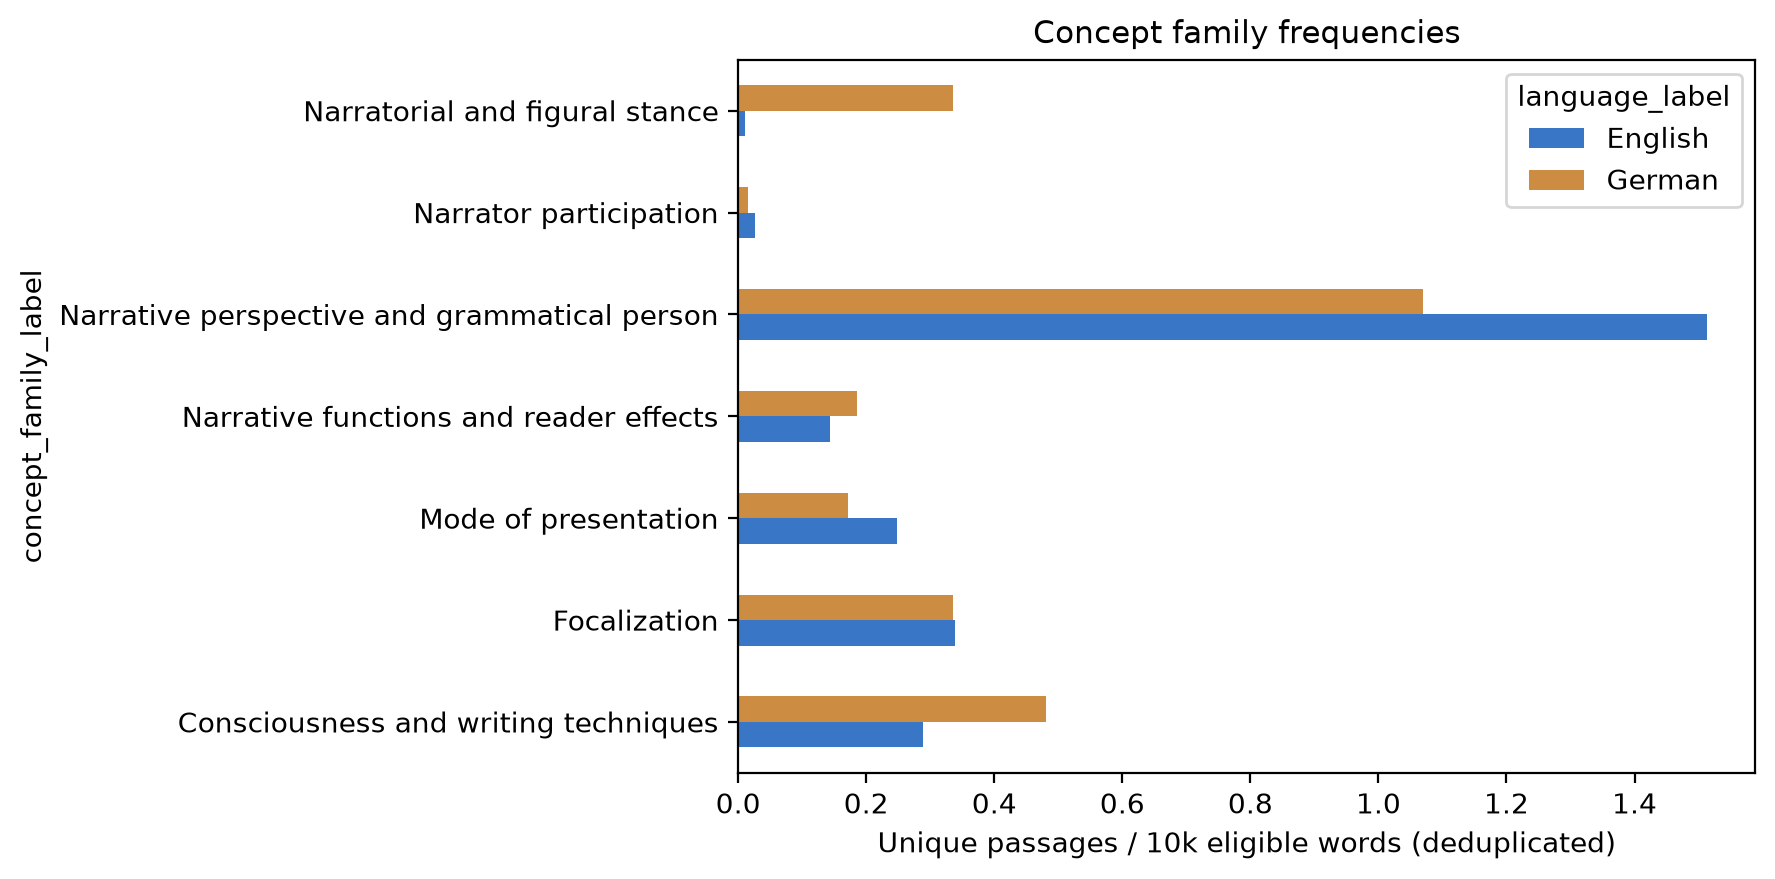

In [6]:
fam = load_t('concept_family_frequencies')
display(fam)
show_fig('06_family_frequencies', 'Family-level unique-passage rates (deduplicated).')


## 6. Book-level dispersion

Includes mean/median/IQR, zero-book share, top-5 contribution and top-10% contribution for **all** concepts.


,concept_id,language,n_books_with_concept,pct_books_with_concept,mean_book_frequency,median_book_frequency,q1_book_frequency,q3_book_frequency,iqr_book_frequency,pct_books_zero,top5_books_contribution,top10pct_books_contribution,top10pct_n_books
0,perspective_general,en,144,32.579186,0.435095,0.000000,0.0,0.134892,0.134892,67.420814,0.435675,0.863457,45
1,voice_general,en,121,27.375566,0.121807,0.000000,0.0,0.091341,0.091341,72.624434,0.246575,0.753425,45
2,grammatical_first_person,en,328,74.208145,0.800489,0.324740,0.0,1.053407,1.053407,25.791855,0.103586,0.472908,45
3,grammatical_second_person,en,170,38.461538,0.147621,0.000000,0.0,0.161310,0.161310,61.538462,0.173913,0.648551,45
4,grammatical_third_person,en,292,66.063348,0.634421,0.242538,0.0,0.895366,0.895366,33.936652,0.125554,0.503693,45
5,voice_heterodiegetic,en,9,2.036199,0.002888,0.000000,0.0,0.000000,0.000000,97.963801,0.600000,1.000000,45
6,voice_homodiegetic,en,16,3.619910,0.004841,0.000000,0.0,0.000000,0.000000,96.380090,0.388889,1.000000,45
7,voice_eyewitness,en,19,4.298643,0.014194,0.000000,0.0,0.000000,0.000000,95.701357,0.547619,1.000000,45
8,voice_participant,en,3,0.678733,0.000848,0.000000,0.0,0.000000,0.000000,99.321267,1.000000,1.000000,45
9,voice_protagonist,en,7,1.583710,0.003878,0.000000,0.0,0.000000,0.000000,98.416290,0.894737,1.000000,45


**Figure.** Frequency versus book prevalence. Quadrant lines are exploratory visual aids only.

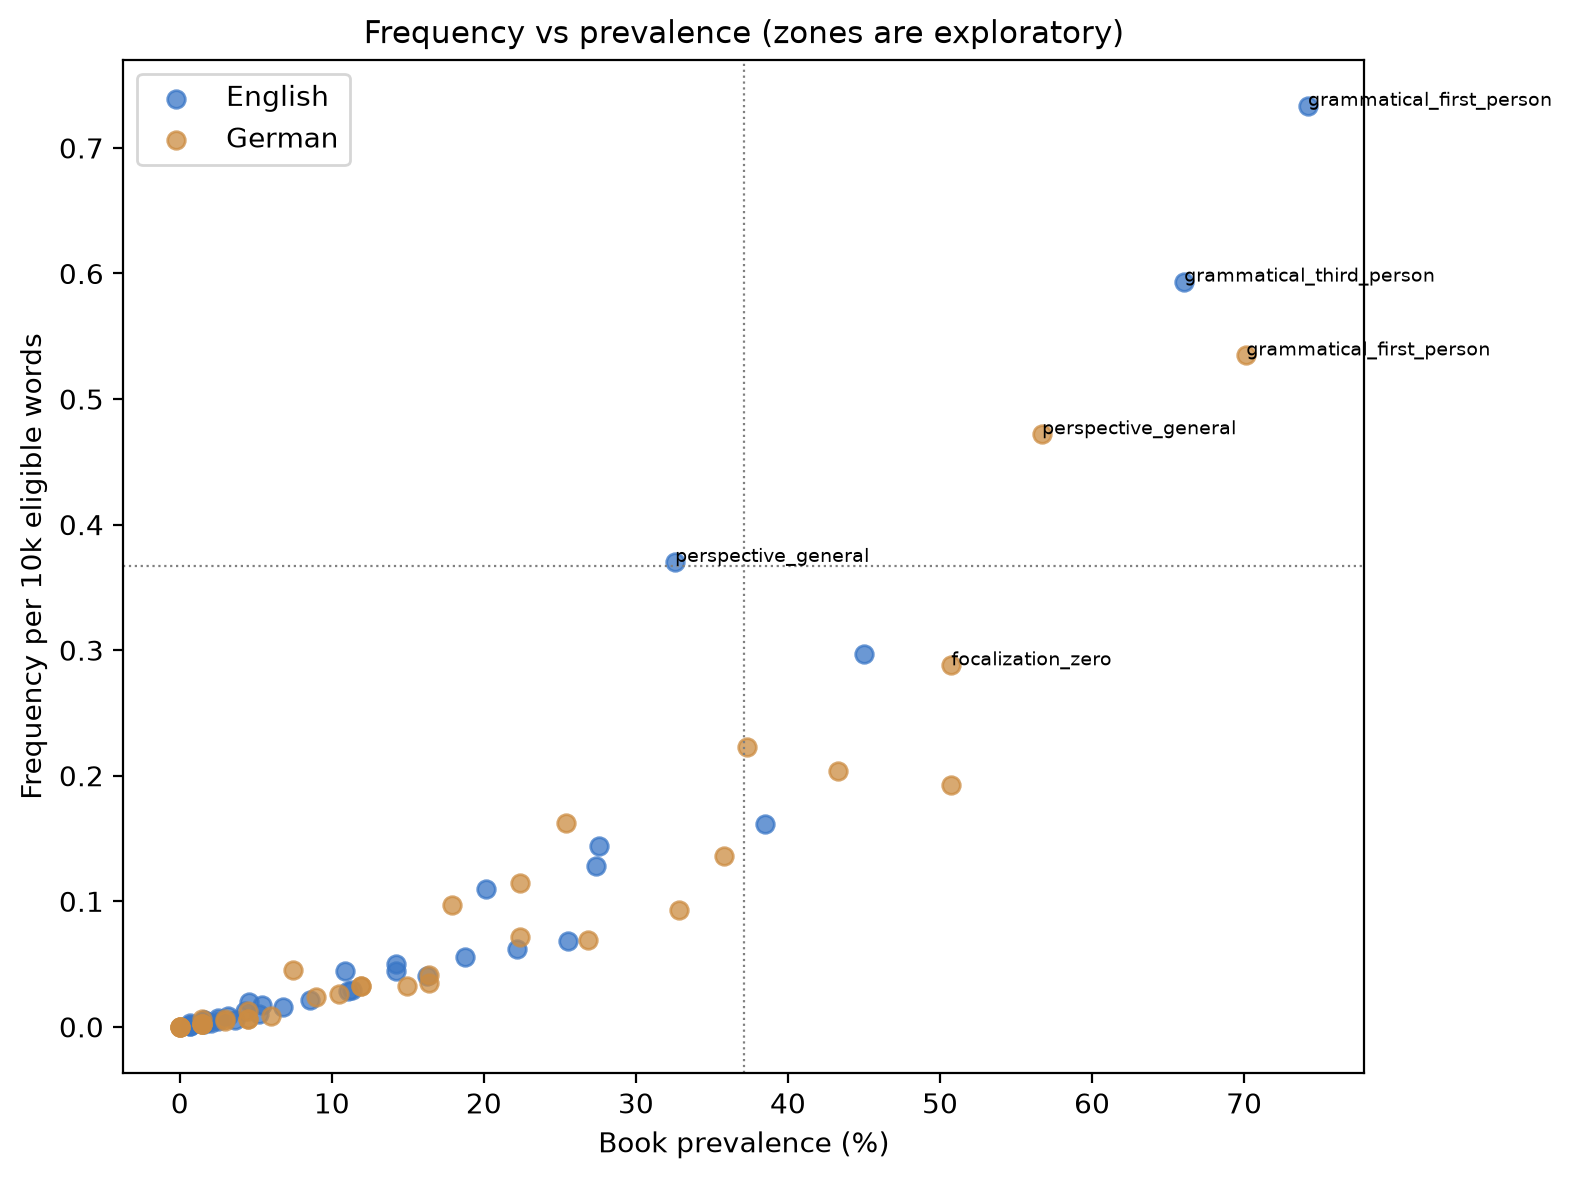

In [7]:
disp = load_t('concept_dispersion')
display(disp.head(12))
show_fig('07_freq_vs_prevalence', 'Frequency versus book prevalence. Quadrant lines are exploratory visual aids only.')


## 7. Category comparison and standardization

Shared weights = mean of English and German category eligible-word shares.

$$f^{standardized}_{l,c}=\sum_g w_g f_{l,c,g}$$

Standardization adjusts composition; it does not eliminate dictionary bias.


,language,primary_group,eligible_words,pct_eligible_words,n_books
0,en,contrast,1741052.0,5.088036,21
1,en,fiction_manual,22396881.0,65.452466,290
2,en,pedagogy_genre_craft,10080611.0,29.459497,131
3,de,contrast,1330345.0,28.800926,11
4,de,fiction_manual,2114370.0,45.774452,38
5,de,pedagogy_genre_craft,1174390.0,25.424622,18


,primary_group,common_weight
0,contrast,0.169445
1,fiction_manual,0.556135
2,pedagogy_genre_craft,0.274421


,concept_id,freq_en_original,freq_de_original,freq_en_standardized,freq_de_standardized,ratio_en_over_de_original,ratio_en_over_de_standardized,sign_of_difference_changed,note
13,focalization_zero,0.296915,0.287935,0.268885,0.297759,1.031189,0.903029,True,Weights = mean of EN and DE category eligible-...
28,information_control,0.049681,0.045463,0.047002,0.054942,1.092763,0.855479,True,Weights = mean of EN and DE category eligible-...
19,pov_object,0.000877,0.002165,0.001470,0.001274,0.404965,1.154009,True,Weights = mean of EN and DE category eligible-...
0,perspective_general,0.370267,0.471953,0.323969,0.540354,0.784542,0.599549,False,Weights = mean of EN and DE category eligible-...
26,switching_consistency,0.017534,0.203503,0.015066,0.210021,0.086163,0.071735,False,Weights = mean of EN and DE category eligible-...
21,mode_dramatic,0.044420,0.071442,0.056098,0.065569,0.621765,0.855549,False,Weights = mean of EN and DE category eligible-...
22,mode_balance,0.016073,0.032474,0.015346,0.037510,0.494957,0.409115,False,Weights = mean of EN and DE category eligible-...
23,consciousness_access,0.061955,0.069277,0.062441,0.075989,0.894298,0.821709,False,Weights = mean of EN and DE category eligible-...
24,thought_representation,0.110174,0.136390,0.099117,0.158995,0.807787,0.623401,False,Weights = mean of EN and DE category eligible-...
25,distance_depth,0.044713,0.023814,0.042604,0.028052,1.877565,1.518736,False,Weights = mean of EN and DE category eligible-...


**Figure.** Share of eligible words by corpus category.

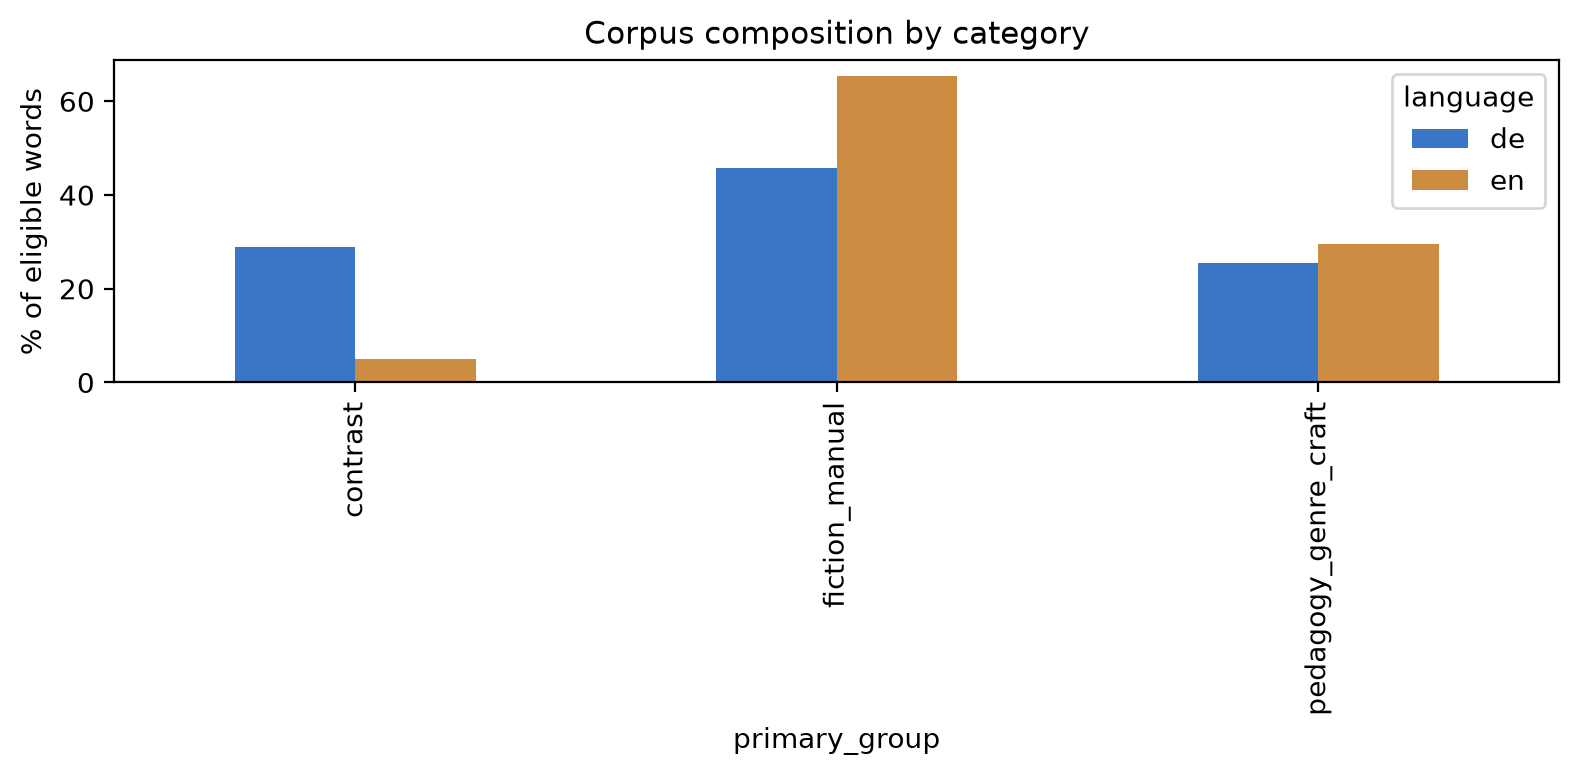

In [8]:
comp = load_t('corpus_composition_by_group')
weights = load_t('standardization_weights')
std = load_t('standardized_frequencies')
display(comp)
display(weights)
display(std.sort_values('sign_of_difference_changed', ascending=False).head(12))
show_fig('08_composition_by_group', 'Share of eligible words by corpus category.')


## 8. Co-occurrence

Passage-level Jaccard with minimum co-occurrence threshold. A second pass excludes extreme-length passages. Overlapping `matched_spans` are flagged where available. Co-occurrence ≠ causality.


,language,concept_a,concept_b,cooccurrence,support_a,support_b,jaccard,conditional_a_given_b,conditional_b_given_a,n_books,n_passages_disjoint_triggers,n_passages_overlapping_evidence
41,en,grammatical_first_person,grammatical_third_person,882,2510,2031,0.241049,0.434269,0.351394,227,830,52
88,en,grammatical_third_person,focalization_zero,470,2031,1016,0.182383,0.462598,0.231413,147,373,97
66,en,grammatical_second_person,grammatical_third_person,243,552,2031,0.103846,0.119645,0.440217,98,243,0
47,en,grammatical_first_person,focalization_zero,324,2510,1016,0.101187,0.318898,0.129084,123,324,0
40,en,grammatical_first_person,grammatical_second_person,267,2510,552,0.095528,0.483696,0.106375,110,267,0
38,en,voice_general,narrative_style_voice,58,438,235,0.094309,0.246809,0.132420,30,1,57
133,en,focalization_internal,focalization_external,9,99,35,0.072000,0.257143,0.090909,6,9,0
118,en,focalization_zero,focalization_internal,67,1016,99,0.063931,0.676768,0.065945,33,43,24
3,en,perspective_general,grammatical_third_person,198,1267,2031,0.063871,0.097489,0.156275,78,145,53
137,en,focalization_internal,distance_depth,15,99,153,0.063291,0.098039,0.151515,9,6,9


,language,concept_a,concept_b,cooccurrence,support_a,support_b,jaccard,conditional_a_given_b,conditional_b_given_a,n_books,n_passages_disjoint_triggers,n_passages_overlapping_evidence
18,de,voice_general,narrative_style_voice,22,53,43,0.297297,0.511628,0.415094,5,0,22
34,de,stance_narratorial,focalization_zero,36,103,133,0.180000,0.270677,0.349515,14,29,7
33,de,stance_narratorial,stance_figural,23,103,75,0.148387,0.306667,0.223301,13,23,0
5,de,perspective_general,stance_figural,37,218,75,0.144531,0.493333,0.169725,14,16,21
1,de,perspective_general,grammatical_first_person,55,218,247,0.134146,0.222672,0.252294,22,40,15
20,de,grammatical_first_person,grammatical_third_person,39,247,89,0.131313,0.438202,0.157895,20,26,13
45,de,focalization_variable,switching_consistency,12,15,94,0.123711,0.127660,0.800000,7,0,12
6,de,perspective_general,focalization_zero,37,218,133,0.117834,0.278195,0.169725,19,35,2
27,de,grammatical_second_person,grammatical_third_person,10,12,89,0.109890,0.112360,0.833333,6,1,9
4,de,perspective_general,stance_narratorial,31,218,103,0.106897,0.300971,0.142202,14,27,4


**Figure.** English co-occurrence heatmap (log1p counts).

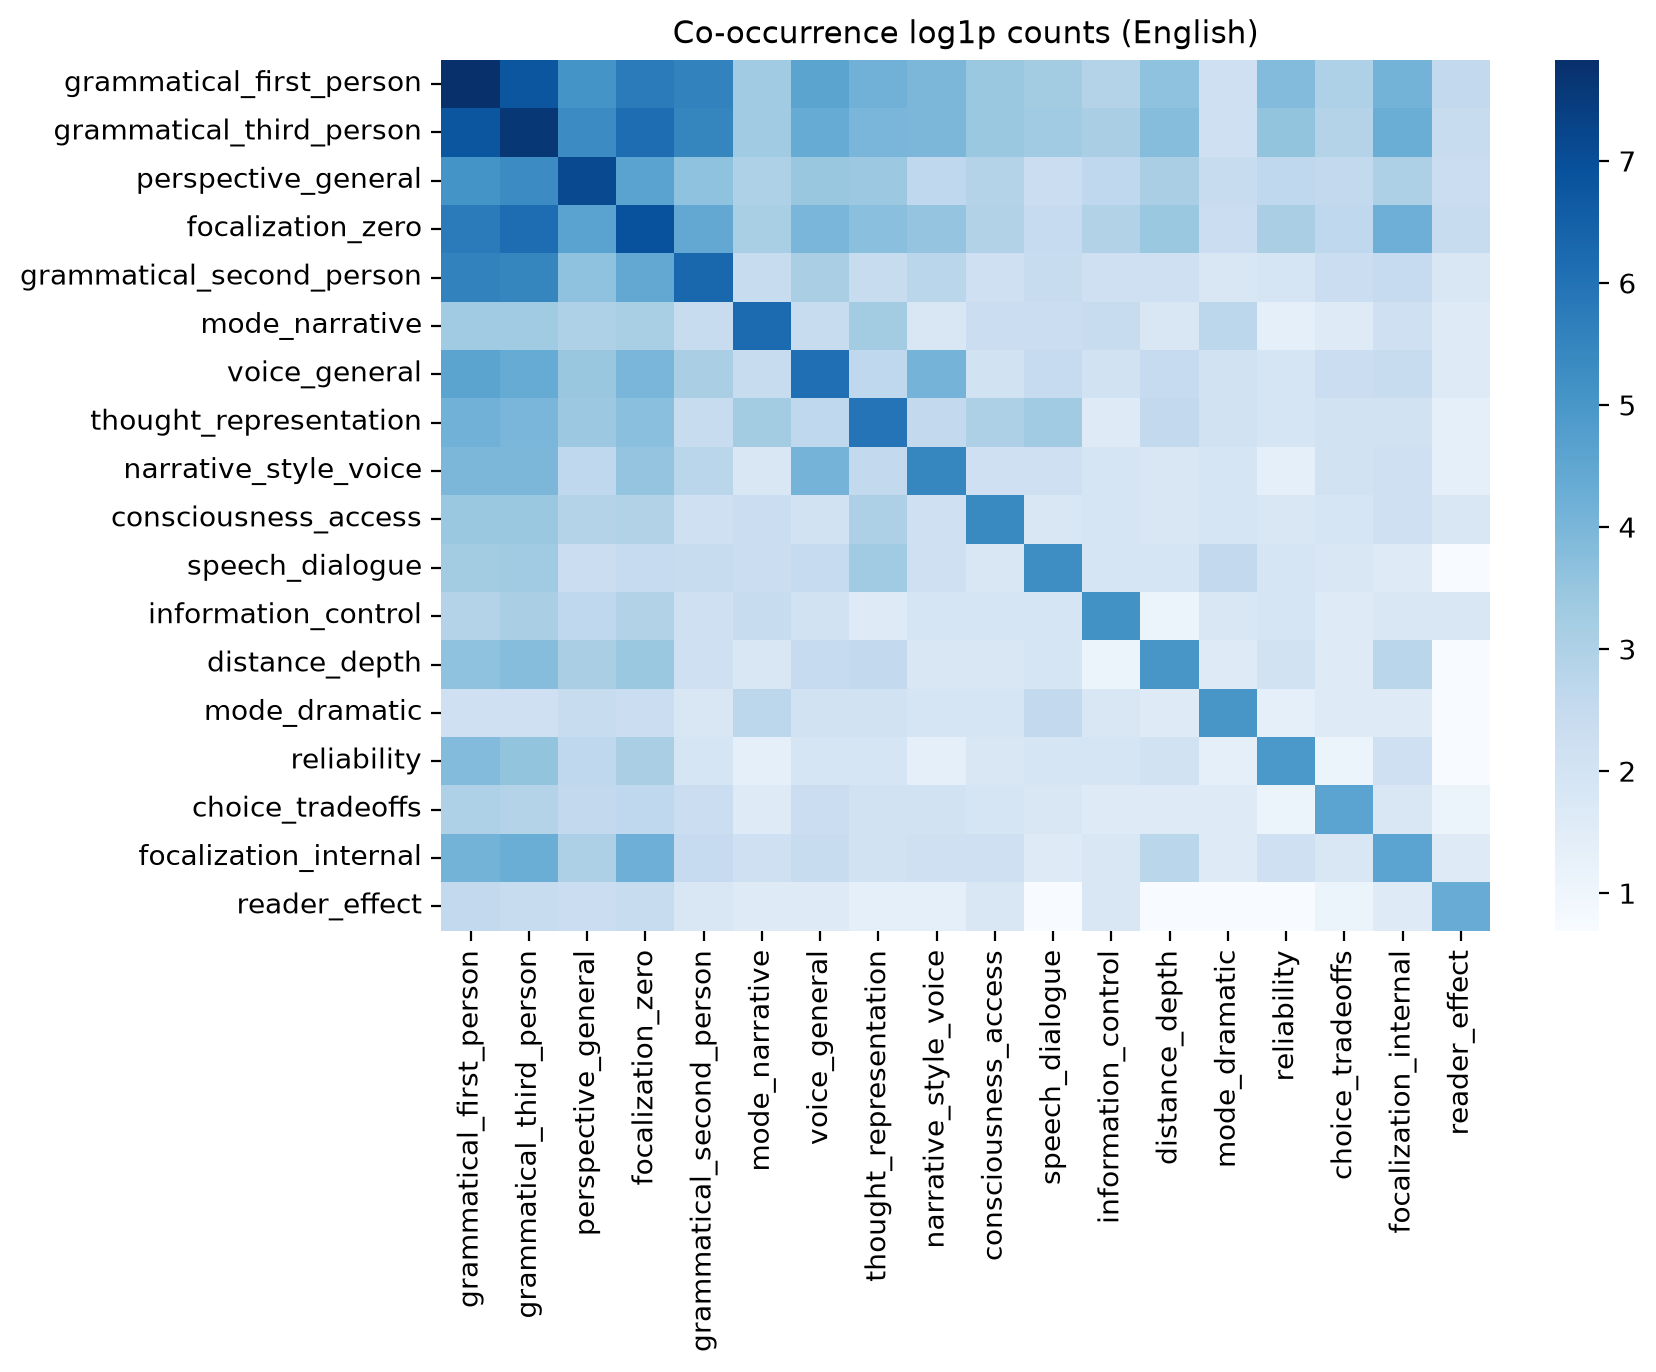

**Figure.** German co-occurrence heatmap (log1p counts).

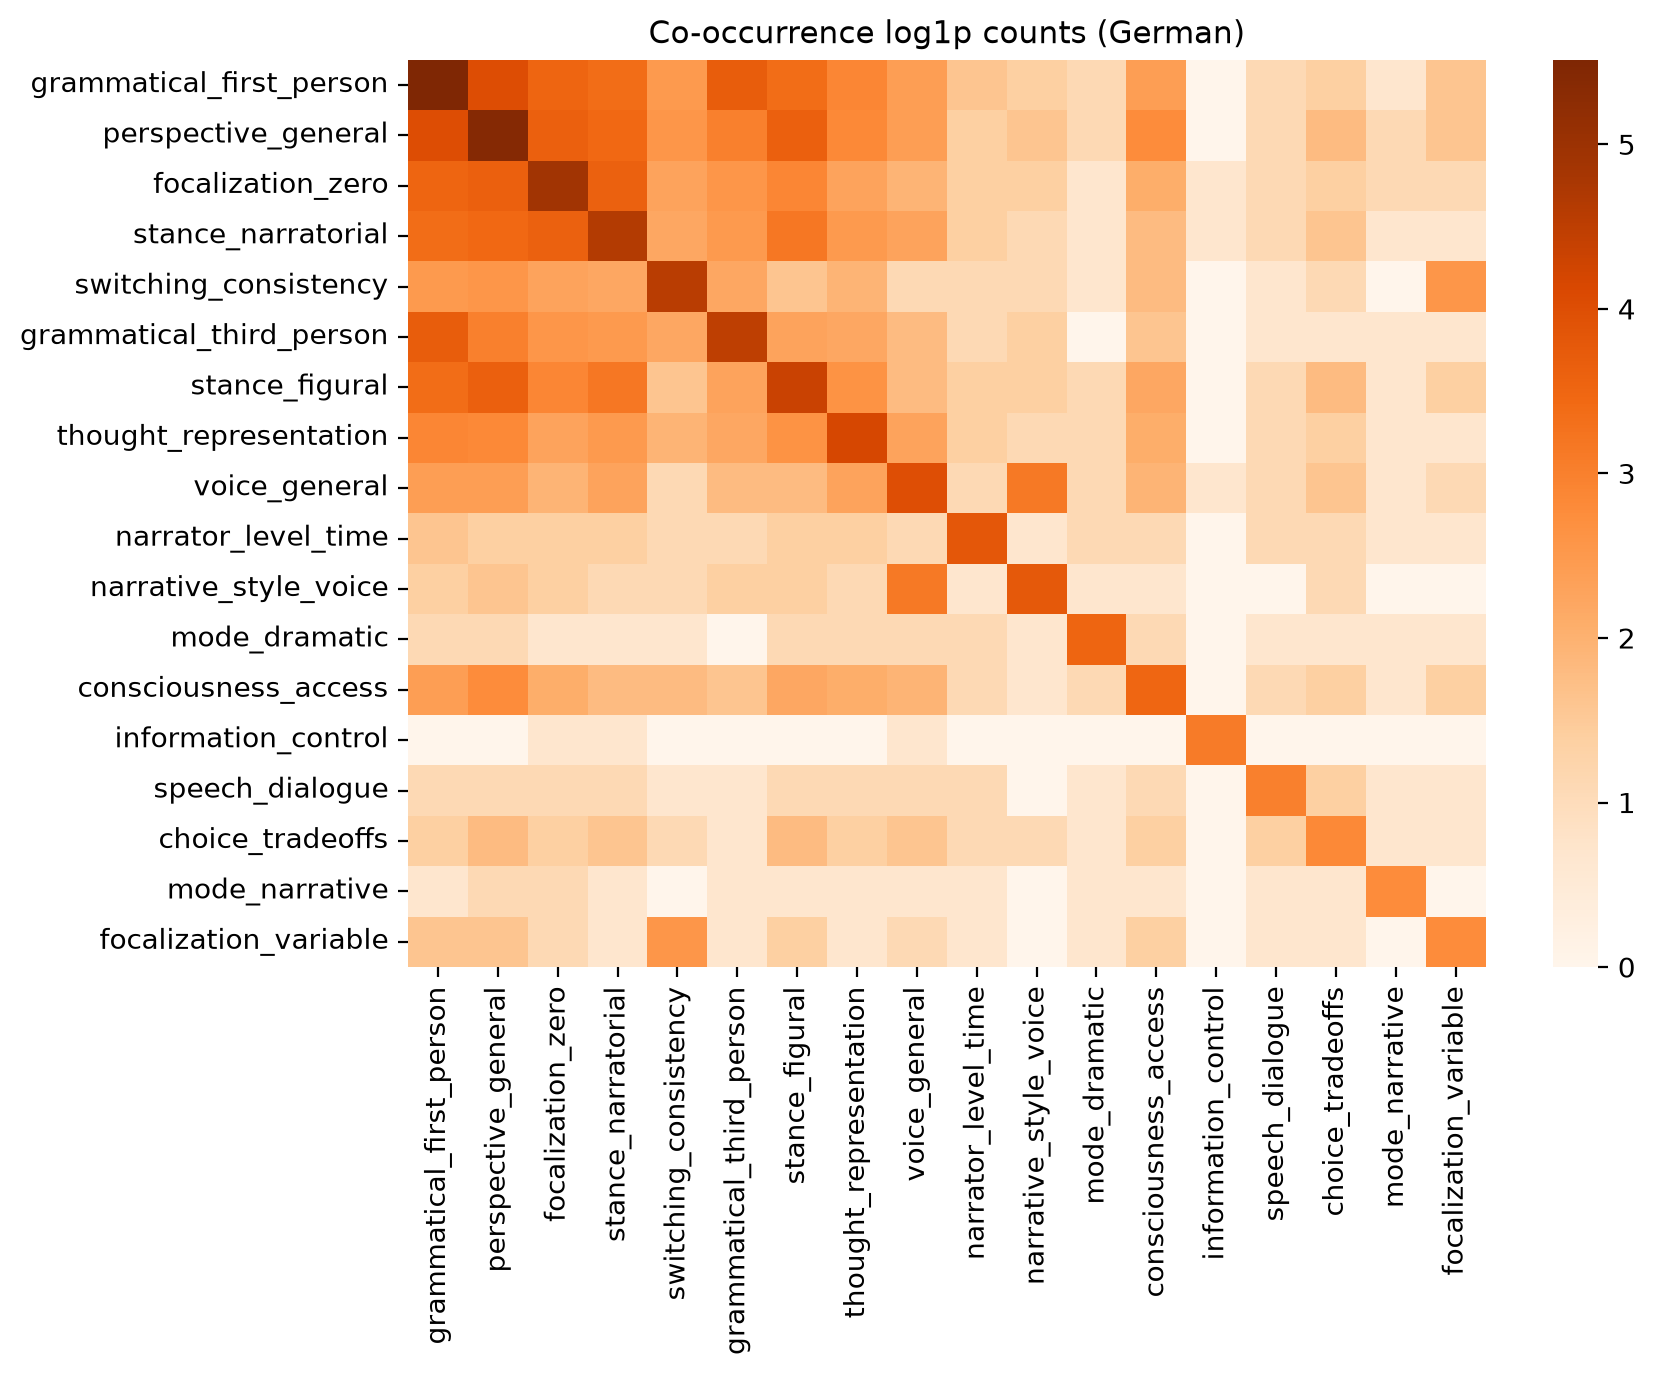

In [9]:
pairs_en = load_t('concept_cooccurrence_pairs_en')
pairs_de = load_t('concept_cooccurrence_pairs_de')
display(pairs_en.sort_values('jaccard', ascending=False).head(10))
display(pairs_de.sort_values('jaccard', ascending=False).head(10))
show_fig('09_cooccurrence_en', 'English co-occurrence heatmap (log1p counts).')
show_fig('09_cooccurrence_de', 'German co-occurrence heatmap (log1p counts).')


## 9. Lexical–BM25 complementarity

L / Bq / Bnew / U. Braw is not available historically and is not reconstructed. Expansion is complementarity, not validated recall.


,language,language_label,n_L_assignments,n_L_passages,n_Bq_assignments,n_Bq_passages,n_Bnew_assignments,n_Bnew_passages,n_lexical_only_passages,n_bm25_only_passages,...,n_lexical_only_assignments,n_bm25_only_assignments,n_shared_assignments,relative_passage_expansion,jaccard_passages_L_vs_Bnew,jaccard_assignments_L_vs_Bnew,braw_available,pool_note,method,version
0,en,English,10643,7380,5756,4204,2812,1778,6422,820,...,10643,2812,0,0.111111,0.116829,0.0,False,Braw not on disk; Bnew from bm25_only_unvalida...,lexical_v03_vs_bm25_v03,v03
1,de,German,1380,941,1339,906,3195,1593,611,1263,...,1380,3195,0,1.342189,0.149728,0.0,False,Braw not on disk; Bnew from bm25_only_unvalida...,lexical_v03_vs_bm25_v03,v03


**Figure.** Lexical versus BM25-new unique passages.

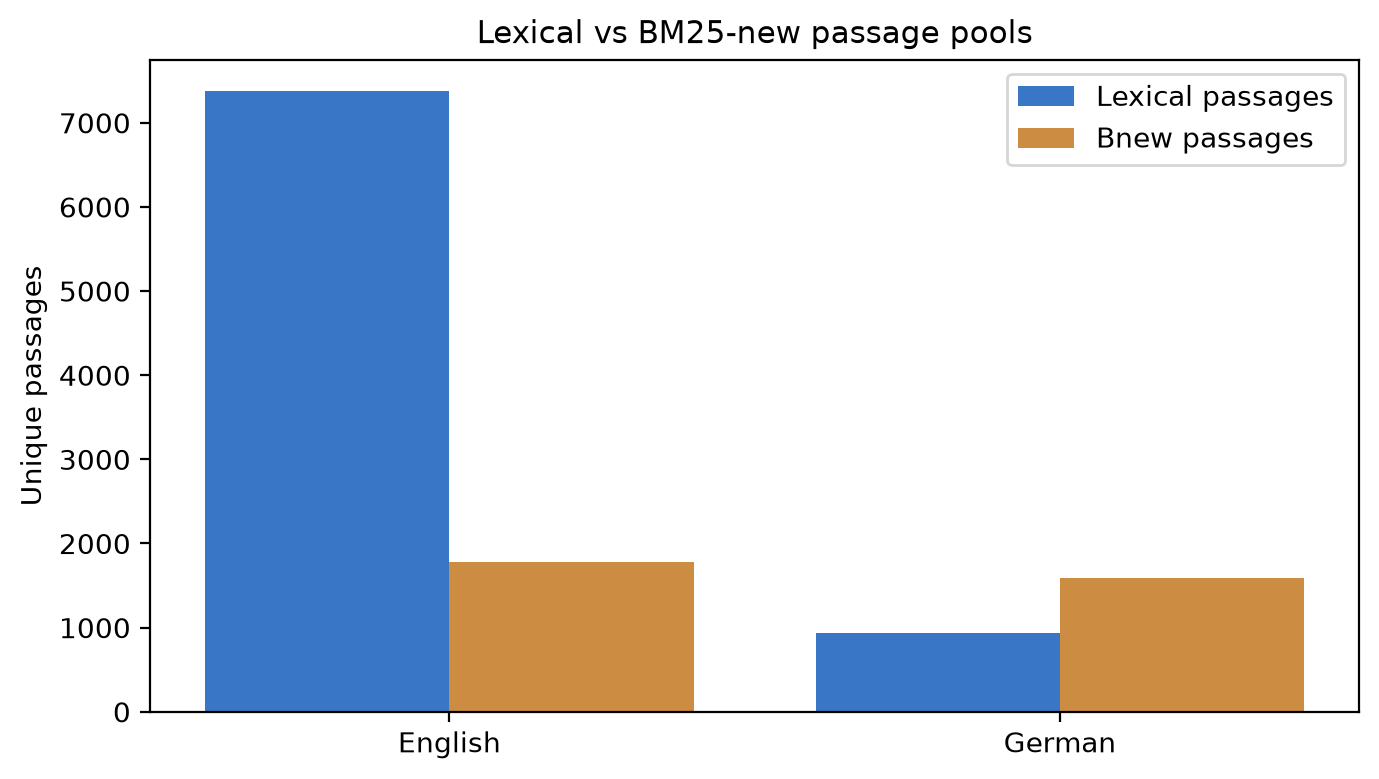

In [10]:
comp_r = load_t('retrieval_complementarity')
display(comp_r)
show_fig('10_complementarity', 'Lexical versus BM25-new unique passages.')


## 10. Sensitivity analysis

Scenarios S1–S11. Focus concepts include `focalization_zero`, stance terms, `grammatical_third_person`, `reader_effect`, `filter_words`. S4 isolates allwissen*/omniscient_de dependence; S7 isolates Stanzel stance vocabulary.


scenario,S1,S10,S11,S2,S3,S4,S5,S6,S7,S8,S9
concept_id,,,,,,,,,,,
filter_words,0.674942,0.455682,0.674554,0.455682,0.695068,0.674942,1.385740,0.674942,0.674942,NaN,0.424821
focalization_zero,1.031189,1.039770,1.030597,1.039770,1.093500,137.148170,1.157570,1.031189,1.031189,1.429383,0.996738
grammatical_third_person,3.080465,2.504987,3.078694,2.504987,3.242571,3.080465,3.402956,3.080465,3.080465,4.336496,2.802328
reader_effect,3.329713,2.464060,3.327799,2.464060,3.104635,3.329713,4.295793,2.834755,3.329713,inf,2.690533
stance_figural,0.032397,0.024303,0.032379,0.024303,0.034753,0.032397,0.041059,0.003648,2.429790,0.011051,0.023259
stance_narratorial,0.020969,0.016877,0.020957,0.016877,0.019462,0.020969,0.023096,0.005242,inf,0.013219,0.016317


,concept_id,robustness
4,grammatical_third_person,sensitive_to_individual_books
10,stance_narratorial,sensitive_to_particular_lexical_rules
11,stance_figural,sensitive_to_particular_lexical_rules
13,focalization_zero,sensitive_to_particular_lexical_rules
31,filter_words,sensitive_to_individual_books
32,reader_effect,sensitive_to_individual_books


**Figure.** EN/DE frequency ratios across sensitivity scenarios for focus concepts.

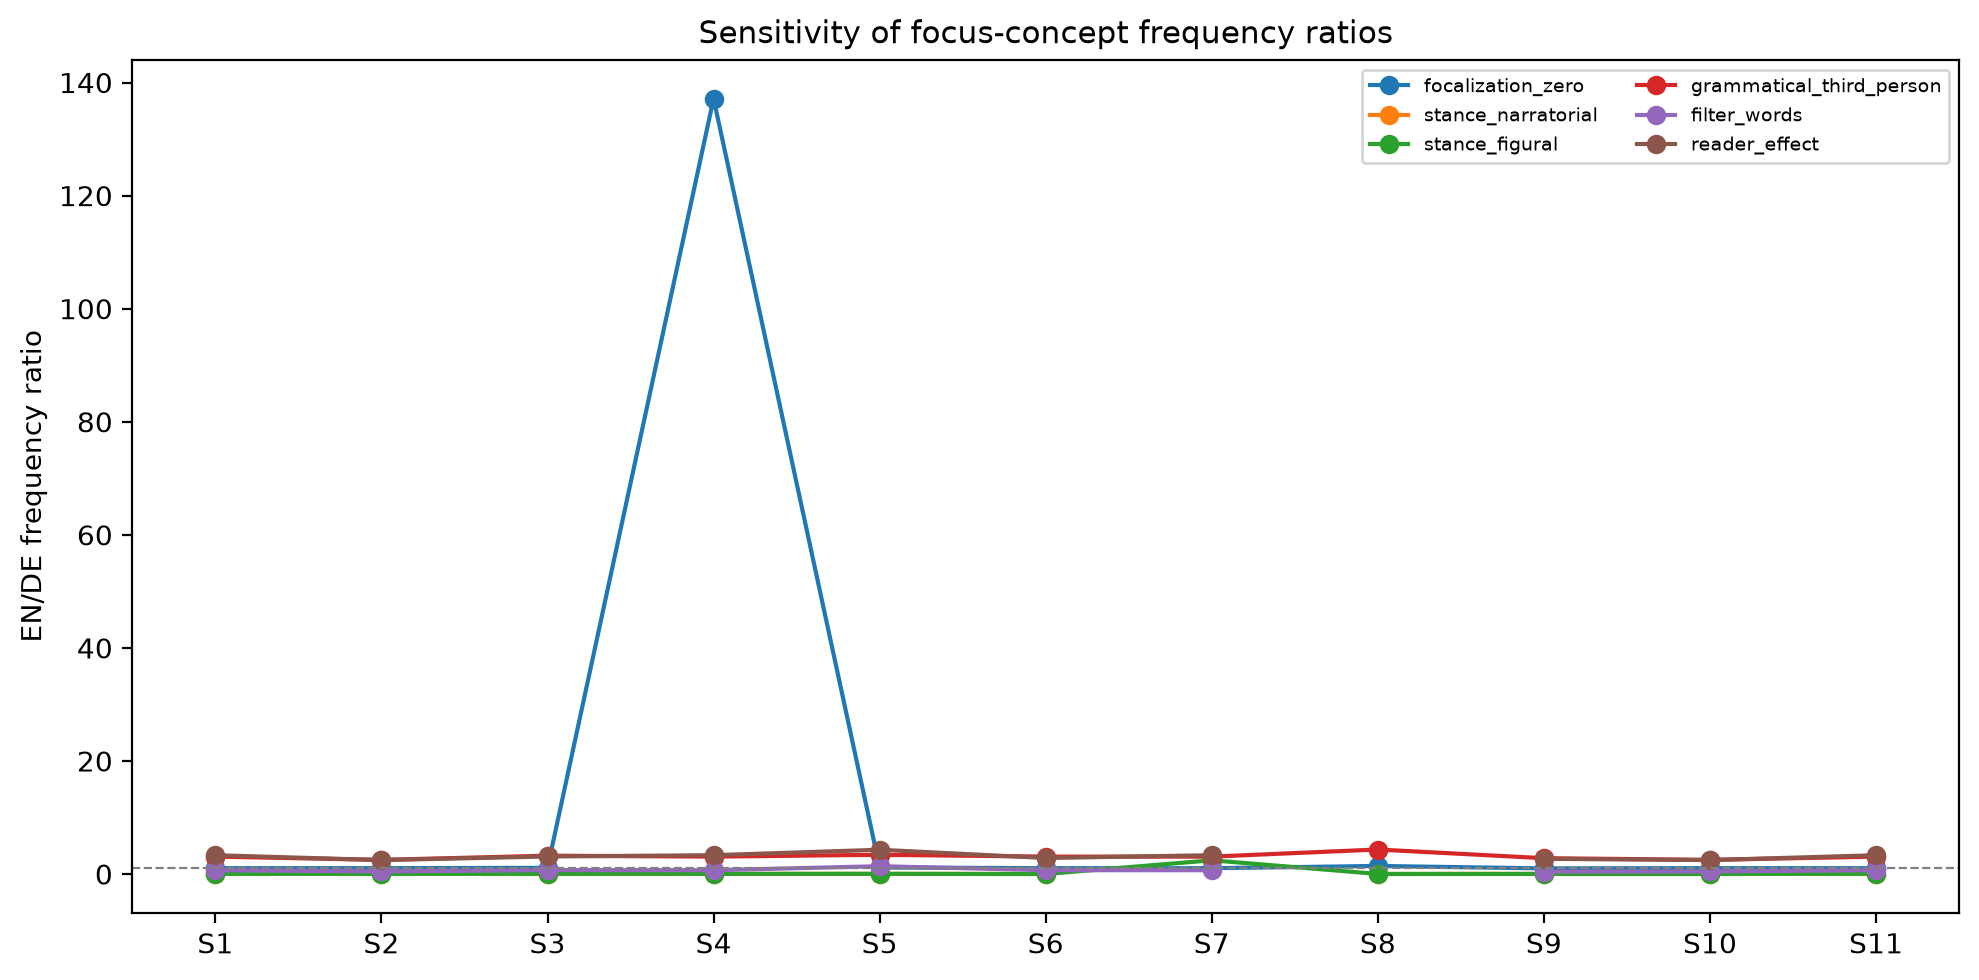

In [11]:
sens = load_t('sensitivity_analysis')
robust = load_t('robustness_labels')
focus = ['focalization_zero','stance_narratorial','stance_figural','grammatical_third_person','filter_words','reader_effect']
display(sens[sens.concept_id.isin(focus)].pivot_table(index='concept_id', columns='scenario', values='frequency_ratio_en_over_de'))
display(robust[robust.concept_id.isin(focus)])
show_fig('11_sensitivity_rr', 'EN/DE frequency ratios across sensitivity scenarios for focus concepts.')


## 11. Uncertainty (book-level bootstrap)

Book resampling within language × category. Intervals do **not** capture dictionary bias. Evaluation precision/recall remain pending.


In [12]:
boot = load_t('bootstrap_intervals')
display(boot.head(18))
print('Eval note: manual labels for v0.5 sample are empty; no precision/recall reported.')


,concept_id,language,estimate_type,point_mean,ci_low,ci_high,n_iter,seed,note
0,focalization_zero,en,frequency_per_10k_eligible,0.296064,0.237521,0.365660,1000,20261122,Book-level stratified bootstrap; does not capt...
1,focalization_zero,de,frequency_per_10k_eligible,0.288901,0.185099,0.421028,1000,20261122,Book-level stratified bootstrap; does not capt...
2,focalization_zero,en_over_de,frequency_ratio,1.070759,0.669289,1.677570,1000,20261122,Book-level stratified bootstrap; does not capt...
3,stance_narratorial,en,frequency_per_10k_eligible,0.004687,0.001754,0.008460,1000,20261122,Book-level stratified bootstrap; does not capt...
4,stance_narratorial,de,frequency_per_10k_eligible,0.224395,0.134070,0.314175,1000,20261122,Book-level stratified bootstrap; does not capt...
5,stance_narratorial,en_over_de,frequency_ratio,0.021993,0.007435,0.048563,1000,20261122,Book-level stratified bootstrap; does not capt...
6,stance_figural,en,frequency_per_10k_eligible,0.005283,0.001188,0.010769,1000,20261122,Book-level stratified bootstrap; does not capt...
7,stance_figural,de,frequency_per_10k_eligible,0.161893,0.068672,0.286179,1000,20261122,Book-level stratified bootstrap; does not capt...
8,stance_figural,en_over_de,frequency_ratio,0.036962,0.006973,0.093251,1000,20261122,Book-level stratified bootstrap; does not capt...
9,grammatical_third_person,en,frequency_per_10k_eligible,0.594535,0.504758,0.685724,1000,20261122,Book-level stratified bootstrap; does not capt...


Eval note: manual labels for v0.5 sample are empty; no precision/recall reported.


## 12. Historical overview

Missing years are a missingness category, not zeros. Concept trends are not claimed from sparse dated German subsets.


,language,decade,n_books
0,de,1980s,1
1,de,1990s,3
2,de,2000s,10
3,de,2010s,9
4,de,2020s,2
5,de,unknown,42
6,en,1960s,8
7,en,1970s,12
8,en,1980s,45
9,en,1990s,68


**Figure.** Books with known year per decade (missing years excluded from the trend line).

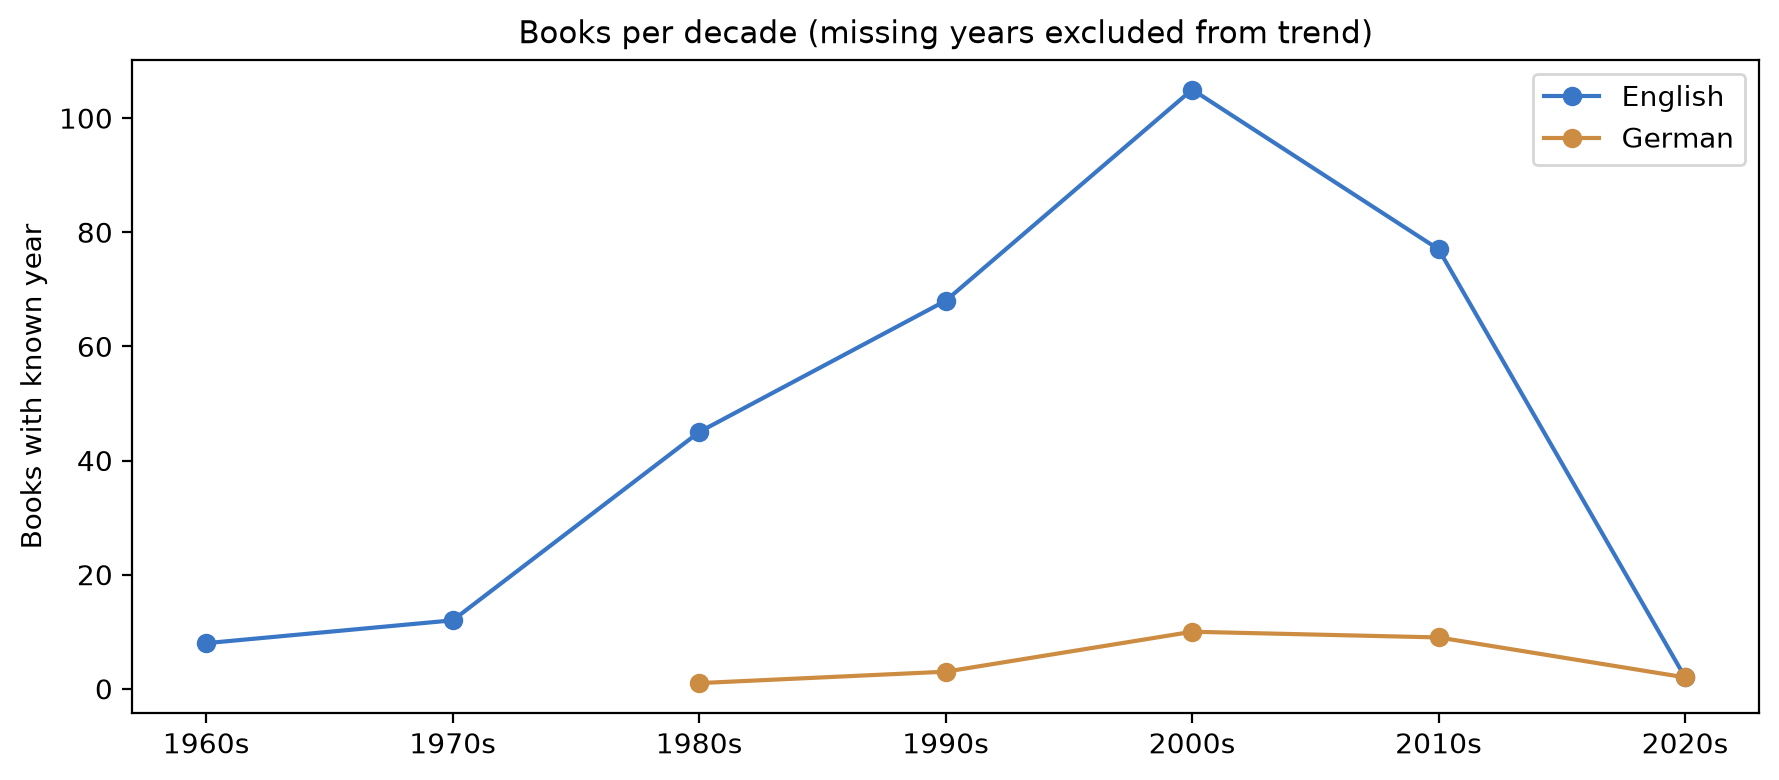

In [13]:
hist = load_t('historical_overview')
display(hist.groupby(['language','decade'], as_index=False)['n_books'].sum().head(30))
show_fig('12_publication_decades', 'Books with known year per decade (missing years excluded from the trend line).')


## 13. Integrity checks

Dynamic assertions against source tables (no hardcoded passage totals).


In [14]:
freq = load_t('concept_frequencies')
cov = load_t('retrieval_coverage')
fam = load_t('concept_family_frequencies')
assert TABLES.is_dir()
assert len(freq) == META['n_concepts'] * 2
assert freq.concept_id.nunique() == META['n_concepts']
assert set(freq.language) == {'en', 'de'}
assert META['validation']['n_missing_passage_keys'] == 0
assert META['validation']['n_duplicate_assignments'] == 0
assert int(cov['retrieved_passages'].sum()) == META['validation']['n_lexical_passages']
assert int(cov['assignments'].sum()) == META['validation']['n_lexical_assignments']
assert fam['note'].str.contains('deduplicat', case=False).all()
print('Integrity checks passed.')


Integrity checks passed.


## 14. Limitations and next steps

- Dictionary bias; asymmetric EN/DE vocabularies.
- No human gold labels yet for the probability sample.
- Extreme passages retained with S3 sensitivity.
- Future dense/hybrid retrieval can append to `02_assignments_long.csv`.

Interactive colleague report: `reports/02_narrative_perspective_interactive.html`.
